# SeDriCa Motion Planning - Q1(d) and Q1(e): grid-based A*

**Part (d)** (sections 1-12): 8-connected A* on a user-defined grid. Edit the **USER INPUT** cell (section 8) and run.

**Part (e)** (sections 13-19): the same planner tested on a road-like map. Edit the **USER INPUT for part (e)** cell (section 15) and run from there.

Coordinates are `(x, y)` = (column, row), origin at the bottom-left.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import heapq


# --------------------------------------------------
# 1. Heuristic function
# --------------------------------------------------

def heuristic(node, goal):
    """
    Octile distance between the current node and goal.

    This is the exact shortest distance on an empty 8-connected
    grid (straight move = 1, diagonal move = sqrt(2)), so it never
    overestimates the true cost and A* stays optimal.
    """

    dx = abs(goal[0] - node[0])
    dy = abs(goal[1] - node[1])

    # Do the diagonal moves first, then the remaining straight moves
    return (dx + dy) + (np.sqrt(2) - 2) * min(dx, dy)

In [2]:
# --------------------------------------------------
# 2. Check whether a node is valid
# --------------------------------------------------

def is_valid(node, grid):
    """
    Checks whether a node is:
    1. Inside the grid
    2. Not an obstacle
    """

    x, y = node

    rows, cols = grid.shape

    # Check grid boundaries
    if x < 0 or x >= cols:
        return False

    if y < 0 or y >= rows:
        return False

    # Check obstacle (0 = free, anything else is blocked)
    if grid[y, x] != 0:
        return False

    return True

In [3]:
# --------------------------------------------------
# 3. Generate 8-connected neighbours
# --------------------------------------------------

def get_neighbours(node, grid):
    """
    Returns the valid neighbours of a node together with
    the cost of moving to each one.

    Straight moves cost 1, diagonal moves cost sqrt(2).
    A diagonal move is not allowed if either of the two cells
    it squeezes between is an obstacle (no cutting corners).
    """

    x, y = node

    directions = [
        (-1, -1), (-1, 0), (-1, 1),
        ( 0, -1),          ( 0, 1),
        ( 1, -1), ( 1, 0), ( 1, 1)
    ]

    neighbours = []

    for dx, dy in directions:

        neighbour = (x + dx, y + dy)

        # Ignore cells outside the grid or on an obstacle
        if not is_valid(neighbour, grid):
            continue

        # Diagonal move
        if dx != 0 and dy != 0:

            # Both side cells must be free
            if not is_valid((x + dx, y), grid):
                continue

            if not is_valid((x, y + dy), grid):
                continue

            movement_cost = np.sqrt(2)

        # Straight move
        else:
            movement_cost = 1

        neighbours.append((neighbour, movement_cost))

    return neighbours

In [4]:
# --------------------------------------------------
# 4. Reconstruct the path
# --------------------------------------------------

def reconstruct_path(came_from, current):
    """
    Reconstructs the path by tracing backwards
    from the goal to the start.
    """

    path = [current]

    while current in came_from:
        current = came_from[current]
        path.append(current)

    path.reverse()

    return path

In [5]:
# --------------------------------------------------
# 5. A* algorithm
# --------------------------------------------------

def astar(grid, start, goal):
    """
    Returns (path, explored).

    path     : list of (x, y) cells from start to goal, or None
    explored : list of cells A* expanded, in the order it expanded them
    """

    # The start and goal must be usable cells
    if not is_valid(start, grid):
        raise ValueError(f"Start {start} is outside the grid or on an obstacle.")

    if not is_valid(goal, grid):
        raise ValueError(f"Goal {goal} is outside the grid or on an obstacle.")

    # Priority queue of (f-score, node)
    open_set = []
    heapq.heappush(open_set, (heuristic(start, goal), start))

    # Stores the previous node
    came_from = {}

    # Cost from start to each node
    g_score = {
        start: 0
    }

    # Nodes already expanded (the closed set), kept in order
    explored = []
    closed = set()

    while open_set:

        # Select node with lowest f-score
        _, current = heapq.heappop(open_set)

        # A node can be pushed more than once if a cheaper route
        # to it is found later. Skip the old, stale entries.
        if current in closed:
            continue

        # Mark node as explored
        closed.add(current)
        explored.append(current)

        # Goal reached
        if current == goal:

            path = reconstruct_path(
                came_from,
                current
            )

            return path, explored

        # Check all valid neighbours
        for neighbour, movement_cost in get_neighbours(current, grid):

            # Already expanded with its best cost
            if neighbour in closed:
                continue

            # Calculate new g-score
            tentative_g = (
                g_score[current]
                + movement_cost
            )

            # If this is a better route
            if (
                neighbour not in g_score
                or tentative_g < g_score[neighbour]
            ):

                # Remember how we reached this node
                came_from[neighbour] = current

                # Update g-score
                g_score[neighbour] = tentative_g

                # Calculate f-score
                f_score = (
                    tentative_g
                    + heuristic(neighbour, goal)
                )

                # Add to priority queue
                heapq.heappush(
                    open_set,
                    (f_score, neighbour)
                )

    # No path exists
    return None, explored

In [6]:
# --------------------------------------------------
# 6. Path length
# --------------------------------------------------

def path_length(path):
    """
    Total length of the path in cell units.
    """

    length = 0

    for (x1, y1), (x2, y2) in zip(path[:-1], path[1:]):
        length += np.sqrt((x2 - x1)**2 + (y2 - y1)**2)

    return length

In [7]:
# --------------------------------------------------
# 7. Visualisation
# --------------------------------------------------

def plot_result(
    grid,
    start,
    goal,
    path,
    explored
):

    rows, cols = grid.shape

    plt.figure(figsize=(8, 8))

    # Display grid with origin at bottom-left
    plt.imshow(
        grid,
        cmap="gray_r",
        origin="lower"
    )

    # Plot explored nodes (all in one call, so one legend entry)
    explored_x = [node[0] for node in explored]
    explored_y = [node[1] for node in explored]

    plt.scatter(
        explored_x,
        explored_y,
        marker=".",
        color="tab:blue",
        alpha=0.5,
        label="Explored nodes"
    )

    # Plot final path
    if path is not None:

        path_x = [node[0] for node in path]
        path_y = [node[1] for node in path]

        plt.plot(
            path_x,
            path_y,
            color="tab:red",
            linewidth=3,
            label="A* path"
        )

    # Plot start
    plt.scatter(
        start[0],
        start[1],
        marker="o",
        color="tab:green",
        s=100,
        label="Start"
    )

    # Plot goal
    plt.scatter(
        goal[0],
        goal[1],
        marker="*",
        color="gold",
        edgecolors="black",
        s=200,
        label="Goal"
    )

    # Axes
    plt.xlabel("x (cell)")
    plt.ylabel("y (cell)")

    plt.xticks(range(cols))
    plt.yticks(range(rows))

    # Draw the grid lines on the cell edges, not through cell centres
    plt.gca().set_xticks(np.arange(-0.5, cols, 1), minor=True)
    plt.gca().set_yticks(np.arange(-0.5, rows, 1), minor=True)
    plt.grid(which="minor")
    plt.tick_params(which="minor", length=0)

    plt.title("Grid A*")
    plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))

    plt.show()

In [8]:
# --------------------------------------------------
# 8. USER INPUT  (change these values)
# --------------------------------------------------

# Grid size (number of cells)
width = 10
height = 10


# Start position (x, y)
start = (1, 1)


# Goal position (x, y)
goal = (8, 8)


# Obstacles (x, y)
obstacles = [
    (4, 0), (4, 1), (4, 2), (4, 3), (4, 4), (4, 5), (4, 6),
    (6, 3), (6, 4), (6, 5), (6, 6), (6, 7), (6, 8), (6, 9)
]

In [9]:
# --------------------------------------------------
# 9. Build the grid
# --------------------------------------------------

grid = np.zeros(
    (height, width)
)

# Add obstacles to grid
for x, y in obstacles:

    if not (0 <= x < width and 0 <= y < height):
        raise ValueError(f"Obstacle {(x, y)} is outside the grid.")

    grid[y, x] = 1

In [10]:
# --------------------------------------------------
# 10. Run A*
# --------------------------------------------------

path, explored = astar(
    grid,
    start,
    goal
)

In [11]:
# --------------------------------------------------
# 11. Display results
# --------------------------------------------------

if path is None:

    print("No path exists.")

else:

    print("Path found!")
    print()

    print("Path:")
    print(path)

    print()

    print(
        "Number of explored nodes:",
        len(explored)
    )

    print(
        "Number of path nodes:",
        len(path)
    )

    print(
        "Path length (cells):",
        round(path_length(path), 2)
    )

Path found!

Path:
[(1, 1), (2, 2), (2, 3), (3, 4), (3, 5), (3, 6), (3, 7), (4, 7), (5, 7), (5, 6), (5, 5), (5, 4), (5, 3), (5, 2), (6, 2), (7, 2), (8, 3), (8, 4), (8, 5), (8, 6), (8, 7), (8, 8)]

Number of explored nodes: 59
Number of path nodes: 22
Path length (cells): 22.24


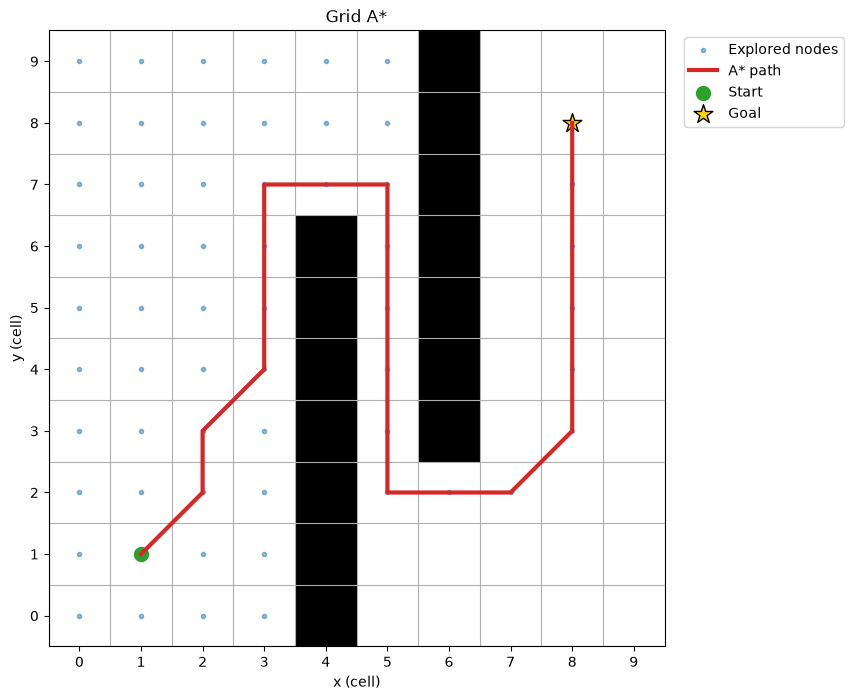

In [12]:
# --------------------------------------------------
# 12. Plot
# --------------------------------------------------

plot_result(
    grid,
    start,
    goal,
    path,
    explored
)

## Part (e): test on a road with a bend and 4 static obstacles

The main road bends north, a 3-block barricade seals it, and 1 more obstacle sits on the service road. The planner has to leave the main road and take the service-road detour.

Cell types on this map: `0` free road, `1` off-road, `2` static obstacle. Part (e) uses its own names (`e_grid`, `e_start`, `plot_road_result`, ...) so it never overwrites part (d).

In [13]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch


# --------------------------------------------------
# 13. Build a road map
# --------------------------------------------------

def build_map(width, height, roads, obstacle_blocks):
    """
    Builds a grid with three kinds of cells:
        0 = free road
        1 = off-road (verge / buildings), cannot be driven on
        2 = static obstacle standing on the road

    roads           : list of rectangles (x0, x1, y0, y1), end values included.
                      The free road is the union of all the rectangles.
    obstacle_blocks : list of rectangles (x0, x1, y0, y1), one per obstacle.
    """

    # Everything starts as off-road
    grid = np.ones(
        (height, width)
    )

    # Carve the roads
    for x0, x1, y0, y1 in roads:

        if not (0 <= x0 <= x1 < width and 0 <= y0 <= y1 < height):
            raise ValueError(f"Road {(x0, x1, y0, y1)} is outside the grid.")

        grid[y0:y1 + 1, x0:x1 + 1] = 0

    # Place the obstacles
    for x0, x1, y0, y1 in obstacle_blocks:

        if not (0 <= x0 <= x1 < width and 0 <= y0 <= y1 < height):
            raise ValueError(f"Obstacle {(x0, x1, y0, y1)} is outside the grid.")

        # An obstacle has to stand on free road and not overlap another one
        if np.any(grid[y0:y1 + 1, x0:x1 + 1] != 0):
            raise ValueError(
                f"Obstacle {(x0, x1, y0, y1)} must sit on free road cells."
            )

        grid[y0:y1 + 1, x0:x1 + 1] = 2

    return grid

In [14]:
# --------------------------------------------------
# 14. Visualisation of the road map
# --------------------------------------------------

def plot_road_result(
    grid,
    start,
    goal,
    path,
    explored,
    title,
    turns=None
):

    rows, cols = grid.shape

    # Scale the figure with the grid so big maps stay readable
    plt.figure(figsize=(cols * 0.3 + 4, rows * 0.3 + 1))

    # Display grid with origin at bottom-left
    # 0 = road (white), 1 = off-road (grey), 2 = obstacle (red)
    plt.imshow(
        grid,
        cmap=ListedColormap(["white", "dimgray", "tab:red"]),
        vmin=0,
        vmax=2,
        origin="lower"
    )

    # Plot explored nodes (all in one call, so one legend entry)
    explored_x = [node[0] for node in explored]
    explored_y = [node[1] for node in explored]

    if explored:

        plt.scatter(
            explored_x,
            explored_y,
            marker=".",
            s=12,
            color="tab:blue",
            alpha=0.5,
            label="Explored nodes"
        )

    # Plot final path
    if path is not None:

        path_x = [node[0] for node in path]
        path_y = [node[1] for node in path]

        plt.plot(
            path_x,
            path_y,
            color="gold",
            linewidth=3,
            label="A* path"
        )

    # Plot start
    plt.scatter(
        start[0],
        start[1],
        marker="o",
        color="tab:green",
        edgecolors="black",
        s=100,
        label="Start"
    )

    # Plot goal
    plt.scatter(
        goal[0],
        goal[1],
        marker="*",
        color="gold",
        edgecolors="black",
        s=200,
        label="Goal"
    )

    # Mark every turn and write its radius (only when turns are given)
    if turns is not None:

        used_labels = set()

        for k, turn in enumerate(turns):

            x, y = turn["vertex"]
            ox, oy = turn["outward"]

            if turn["ok"]:
                colour = "tab:green"
                label = "Turn the buggy can execute"
            else:
                colour = "red"
                label = "Turn tighter than R_min"

            # Only the first marker of each kind gets a legend entry
            if label in used_labels:
                label = None
            else:
                used_labels.add(label)

            # Ring around the turn
            plt.scatter(
                x,
                y,
                s=180,
                facecolors="none",
                edgecolors=colour,
                linewidths=2.5,
                zorder=5,
                label=label
            )

            # Radius label, placed away from the inside of the turn
            # (labels cycle through three distances so neighbours do not overlap)
            distance = [34, 54, 74][k % 3]

            plt.annotate(
                f"R = {turn['radius']:.2f} m",
                xy=(x, y),
                xytext=(distance * ox, distance * oy),
                textcoords="offset points",
                ha="center",
                va="center",
                fontsize=9,
                fontweight="bold",
                color=colour,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=colour, lw=0.8),
                arrowprops=dict(arrowstyle="-", color=colour, lw=1),
                zorder=6
            )

    # Axes
    plt.xlabel("x (cell)")
    plt.ylabel("y (cell)")

    # Label every cell on small grids, every 5th cell on big ones
    step = 1 if max(rows, cols) <= 20 else 5

    plt.xticks(range(0, cols, step))
    plt.yticks(range(0, rows, step))

    # Draw the grid lines on the cell edges, not through cell centres
    plt.gca().set_xticks(np.arange(-0.5, cols, 1), minor=True)
    plt.gca().set_yticks(np.arange(-0.5, rows, 1), minor=True)
    plt.grid(which="minor", linewidth=0.3)
    plt.tick_params(which="minor", length=0)

    # Legend: the explored/path/start/goal entries plus the three cell types
    handles, labels = plt.gca().get_legend_handles_labels()

    handles += [
        Patch(facecolor="white", edgecolor="black", label="Road"),
        Patch(facecolor="dimgray", label="Off-road"),
        Patch(facecolor="tab:red", label="Static obstacle")
    ]

    plt.title(title)
    plt.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.02, 1))

    plt.show()

In [15]:
# --------------------------------------------------
# 15. USER INPUT for part (e)  (change these values)
# --------------------------------------------------
# Every road is a union of rectangles (x0, x1, y0, y1), ends included.
# Every obstacle is one rectangle in the same format.
# Coordinates are (x, y) = (column, row), origin at the bottom-left.

# Grid size (number of cells)
e_width = 30
e_height = 18


# Road: the main road bends north at x = 11..14, and a service
# road at x = 21..24 runs parallel to it and rejoins the top road.
e_roads = [
    (1, 24, 2, 5),      # bottom road, heading east
    (11, 14, 2, 15),    # main road, bending north
    (11, 28, 12, 15),   # top road, heading east
    (21, 24, 2, 15)     # service road (the detour)
]


# Static obstacles (4)
e_obstacles = [
    (11, 11, 8, 9),     # barricade, left block
    (12, 13, 8, 9),     # barricade, middle block
    (14, 14, 8, 9),     # barricade, right block
    (21, 22, 7, 8)      # obstacle on the service road
]


# Start position (x, y)
e_start = (2, 3)


# Goal position (x, y)
e_goal = (27, 14)

In [16]:
# --------------------------------------------------
# 16. Build the map
# --------------------------------------------------

e_grid = build_map(
    e_width,
    e_height,
    e_roads,
    e_obstacles
)

In [17]:
# --------------------------------------------------
# 17. Run A* on the road map
# --------------------------------------------------

e_path, e_explored = astar(
    e_grid,
    e_start,
    e_goal
)

In [18]:
# --------------------------------------------------
# 18. Display results
# --------------------------------------------------

if e_path is None:

    print("No path exists.")

else:

    print("Path found!")
    print()

    print("Path:")
    print(e_path)

    print()

    print(
        "Number of explored nodes:",
        len(e_explored)
    )

    print(
        "Number of path nodes:",
        len(e_path)
    )

    print(
        "Path length (cells):",
        round(path_length(e_path), 2)
    )

    print(
        "Free road cells:",
        int(np.sum(e_grid == 0))
    )

Path found!

Path:
[(2, 3), (3, 3), (4, 4), (5, 5), (6, 5), (7, 5), (8, 5), (9, 5), (10, 5), (11, 5), (12, 5), (13, 5), (14, 5), (15, 5), (16, 5), (17, 5), (18, 5), (19, 5), (20, 5), (21, 5), (22, 6), (23, 6), (23, 7), (23, 8), (23, 9), (23, 10), (24, 11), (24, 12), (25, 12), (26, 13), (27, 14)]

Number of explored nodes: 112
Number of path nodes: 31
Path length (cells): 32.49
Free road cells: 204


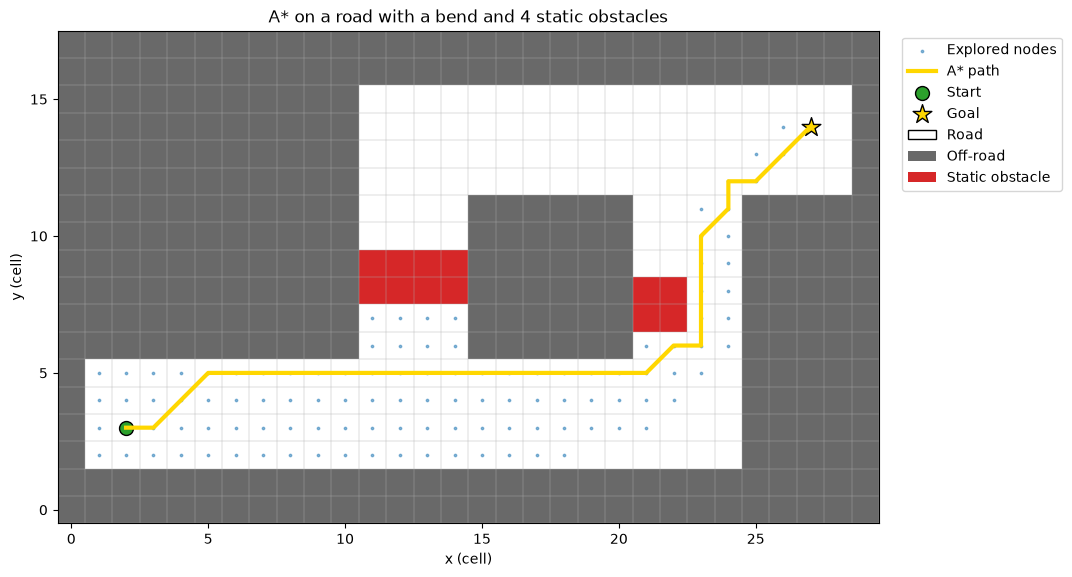

In [19]:
# --------------------------------------------------
# 19. Plot
# --------------------------------------------------

plot_road_result(
    e_grid,
    e_start,
    e_goal,
    e_path,
    e_explored,
    "A* on a road with a bend and 4 static obstacles"
)

## Part (f): can the buggy execute this path?

**Assumption:** the buggy drives only perfect circular arcs. Its tightest arc is `R_min = wheelbase / tan(max steer angle) = 2.30 / tan(32 deg) = 3.68 m`.

**How the radius at each turn is calculated**
1. A *turn* is a path node where the direction changes. The straight pieces of path between turns are *legs*.
2. The turn angle `theta` is the angle between the incoming and outgoing directions.
3. The corner is replaced by the circular arc that touches both legs, a distance `t` from the corner. The right triangle (corner, tangent point, arc centre) gives `R = t / tan(theta / 2)`.
4. A leg is shared with the neighbouring turn, so each turn may use at most half of its shorter leg: `t = (shorter leg) / 2`. This is the largest arc the path allows.
5. Example: a 90 deg turn between two 1 m legs gives `t = 0.5 m`, so `R = 0.5 / tan(45 deg) = 0.50 m`.
6. The turn is executable only if `R >= R_min`.

In [20]:
# --------------------------------------------------
# 20. USER INPUT for part (f)  (change these values)
# --------------------------------------------------

# Buggy wheelbase (m), from the platform spec
wheelbase = 2.30


# Maximum road-wheel steering angle (degrees), from the platform spec
max_steer_deg = 32


# Size of one grid cell (m)
cell_size = 1.0


# Minimum turning radius of the bicycle model: R = L / tan(delta)
min_radius = wheelbase / np.tan(np.radians(max_steer_deg))

print("Minimum turning radius:", round(min_radius, 2), "m")

Minimum turning radius: 3.68 m


In [21]:
# --------------------------------------------------
# 21. Find the turns and their radii
# --------------------------------------------------

def find_turns(path, cell_size, min_radius):
    """
    Returns one dictionary per turn in the path.

    A turn is a path node where the direction changes.
    Each turn is replaced by the largest circular arc that touches
    both straight legs (see the markdown cell above), and its radius
    is compared with the buggy's minimum turning radius.
    """

    # Keep only the nodes where the direction changes (plus start and goal)
    corners = [path[0]]

    for before, node, after in zip(path, path[1:], path[2:]):

        step_in = (node[0] - before[0], node[1] - before[1])
        step_out = (after[0] - node[0], after[1] - node[1])

        if step_in != step_out:
            corners.append(node)

    corners.append(path[-1])

    turns = []

    for i in range(1, len(corners) - 1):

        before = np.array(corners[i - 1])
        node = np.array(corners[i])
        after = np.array(corners[i + 1])

        # Vectors along the two legs (in cells)
        leg_in = node - before
        leg_out = after - node

        # Leg lengths in metres
        length_in = np.linalg.norm(leg_in) * cell_size
        length_out = np.linalg.norm(leg_out) * cell_size

        # Unit directions of travel
        dir_in = leg_in / np.linalg.norm(leg_in)
        dir_out = leg_out / np.linalg.norm(leg_out)

        # Turn angle between the two directions
        angle = np.arccos(np.clip(np.dot(dir_in, dir_out), -1, 1))

        # Each turn may use at most half of the shorter leg
        tangent_length = min(length_in, length_out) / 2

        radius = tangent_length / np.tan(angle / 2)

        # Direction pointing away from the inside of the turn (for labels)
        outward = dir_in - dir_out
        outward = outward / np.linalg.norm(outward)

        turns.append({
            "vertex": tuple(int(v) for v in node),
            "angle": np.degrees(angle),
            "legs": (length_in, length_out),
            "radius": radius,
            "ok": radius >= min_radius,
            "outward": tuple(outward)
        })

    return turns


turns = find_turns(
    e_path,
    cell_size,
    min_radius
)

In [22]:
# --------------------------------------------------
# 22. Display results
# --------------------------------------------------

print(f"Minimum turning radius: {min_radius:.2f} m")
print()

print(f"{'Turn at':<10}{'Angle':>7}{'Legs (m)':>16}{'Radius (m)':>13}   Verdict")
print("-" * 62)

for turn in turns:

    legs = f"{turn['legs'][0]:.2f}, {turn['legs'][1]:.2f}"
    verdict = "OK" if turn["ok"] else "too tight"

    print(
        f"{str(turn['vertex']):<10}"
        f"{turn['angle']:>6.0f}°"
        f"{legs:>16}"
        f"{turn['radius']:>13.2f}   {verdict}"
    )

print()

bad_turns = [t for t in turns if not t["ok"]]

print(
    "Turns the buggy cannot execute:",
    len(bad_turns),
    "of",
    len(turns)
)

Minimum turning radius: 3.68 m

Turn at     Angle        Legs (m)   Radius (m)   Verdict
--------------------------------------------------------------
(3, 3)        45°      1.00, 2.83         1.21   too tight
(5, 5)        45°     2.83, 16.00         3.41   too tight
(21, 5)       45°     16.00, 1.41         1.71   too tight
(22, 6)       45°      1.41, 1.00         1.21   too tight
(23, 6)       90°      1.00, 4.00         0.50   too tight
(23, 10)      45°      4.00, 1.41         1.71   too tight
(24, 11)      45°      1.41, 1.00         1.21   too tight
(24, 12)      90°      1.00, 1.00         0.50   too tight
(25, 12)      45°      1.00, 2.83         1.21   too tight

Turns the buggy cannot execute: 9 of 9


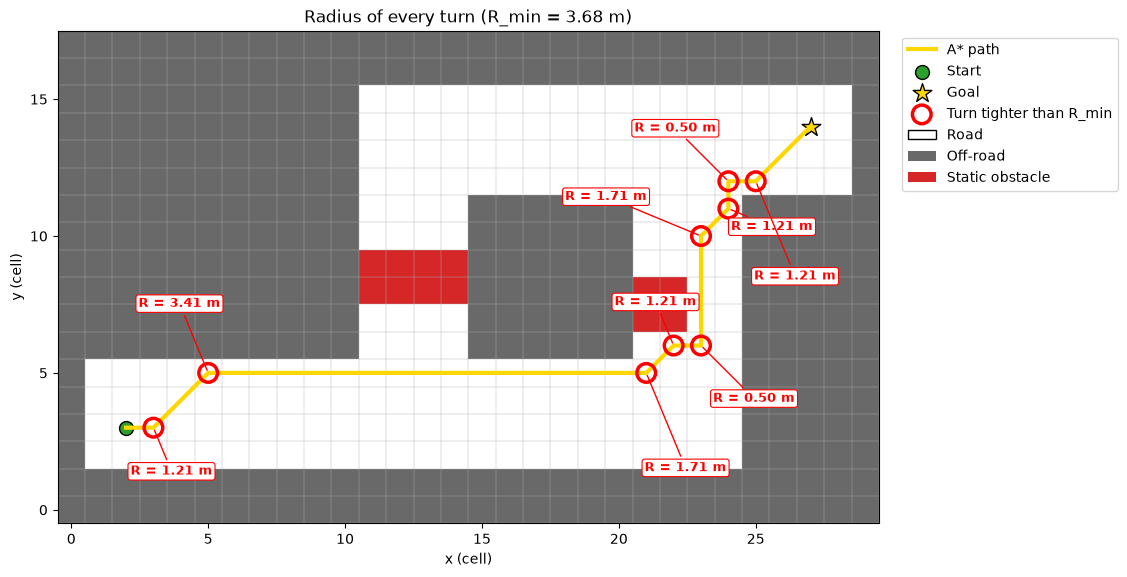

In [23]:
# --------------------------------------------------
# 23. Plot the turns
# --------------------------------------------------

plot_road_result(
    e_grid,
    e_start,
    e_goal,
    e_path,
    [],
    f"Radius of every turn (R_min = {min_radius:.2f} m)",
    turns
)

### Conclusion and fix

**Result:** every turn on the A* path needs a radius of at least `R_min`, but the path only allows far smaller arcs. None of the turns can be executed, so the buggy cannot follow this path.

**Why:** grid A* only knows where the buggy is, `(x, y)`. It moves between neighbouring cells, so the heading jumps by 45 or 90 degrees within one or two cells. It has no idea that the buggy has a heading and a steering limit.

**Fix (not implemented here): Hybrid A\* with longer, wider routes**
- Add the heading `theta` (angle from the +x axis) to the state, so a node is `(x, y, theta)`.
- Generate the next nodes by driving the bicycle model forward a short distance with a steering angle of at most 32 deg, so every segment is a real arc and none is tighter than `R_min`.
- Because the planner tracks the heading, it can plan a turn ahead of time. Where there is free space earlier on the road, it swings wide and enters the turn with the right orientation, so the turn becomes one large drivable arc instead of a sharp corner.
- Where a direct turn is too tight, the planner can choose a longer route (a wider detour, a loop or a roundabout) that lets the buggy approach with the right heading. The shorter path is only kept if the buggy can actually drive it.
- The price is a longer path, but it is one the buggy can follow. If no route has enough room, the planner reports that there is no path, instead of returning one the buggy cannot drive.